# DeBERTa full walkthrough: nbev

Our model, **nbev** ("new BEV"), from data to answers. The heavy lifting lives in the repo's scripts; each cell here is one step.

```
 [CLS] task + question + state [SEP]  [OPT] Billing [SEP]  [OPT] Technical [SEP]  [OPT] Sales [SEP]
 positions: 0 ................ n-1     n    n+1 ...         n    n+1 ...           n    n+1 ...
                                       every candidate restarts at position n (as in BEV)
                    |
                 DeBERTa              ONE sequence per question; the attention mask lets a candidate
                    |                 see the context and itself, never another candidate
                    |
          h1               h2               h3           one 768-d vector per candidate: its [OPT] token
          |                |                |
    +-----------------------------------------------+
    |  self-attention between the candidates  (x2)  |
    +-----------------------------------------------+
          |                |                |
         h1'              h2'              h3'           no positions: order doesn't matter
          |                |                |
         MLP              MLP              MLP           the same MLP for every candidate
          |                |                |
          z1               z2               z3           one score (logit) per candidate
          |                |                |
    +-----------------------------------------------+
    |              softmax(z / T_task)              |
    +-----------------------------------------------+
          |                |                |
     P(Billing)      P(Technical)       P(Sales)         calibrated probabilities
```

| step | what happens | code |
|---|---|---|
| 1. Data | four splits that never share a state | `dataset.py` |
| 2. Encoding | one packed DeBERTa sequence per question | `architectures/nbev/tokenization.py` |
| 3. Training | full fine-tuning, best checkpoint picked on validation | `train.py` + `configs/deberta_walkthrough.yaml` |
| 4. The model | encoder + decision head | `architectures/nbev/network.py`, `architectures/choice_head.py` |
| 5. Calibration | one temperature per question type | `calibration.py`, `metrics.py` |
| 6. Test | final numbers, measured once, and inference speed | `metrics.py` |
| 7. Reading the results | baselines, the yes/no threshold, score errors, accuracy per domain | `notebook_utils.py` |
| 8. Hands-on | ask your own questions | `inference.py` (`answer`) |

**Nothing is overwritten.** If a finished run already exists, it's reused instead of retrained. Model outputs are cached next to the checkpoint, and calibration and test results are only written if they don't exist yet. The first run trains for about 25–30 minutes; after that, the whole notebook runs in about a minute.

Kernel: the project's `.venv` (Python 3.10).

In [1]:
import json
import os

import pandas as pd
import yaml

from architectures import get_architecture
from calibration import fit_temperatures, save_temperatures
from dataset import TASK_NAMES, TASK_TYPES, load_questions
from inference import get_device
from logger import load_checkpoint
from metrics import compute_metrics
from notebook_utils import (accuracy_by, ask, baseline_table, evaluate_split, head_attention,
                            inference_speed, layer_summary, parameter_table, plot_calibration, plot_head_attention, plot_noul_threshold,
                            plot_score_errors, plot_test_results, plot_training_curves, show_model_input, show_question,
                            train_or_load)

CONFIG_PATH = "configs/deberta_walkthrough.yaml"  # everything about the model and its training
RUN_NAME = "nbev-walkthrough"                     # results go to runs/<RUN_NAME>-<timestamp>/
RETRAIN = False                                   # True: train a new run even if a finished one exists
NUM_CALIBRATION = 1000                            # questions used to fit the temperatures
NUM_TEST = 1000                                   # questions used for the final numbers

config = yaml.safe_load(open(CONFIG_PATH))
if os.environ.get("NOTEBOOK_QUICK_RUN") == "1":   # tiny sizes, only used to check that every cell runs
    RUN_NAME, NUM_CALIBRATION, NUM_TEST = RUN_NAME + "-quick", 40, 24
    config["data"].update(max_train_questions=24, max_test_questions=16)
    config["optim"]["grad_accum_steps"] = 2
    config["logging"].update(log_every=1, eval_every=2)

device = get_device()
pd.options.display.float_format = "{:.4f}".format
m, d, o = config["model"], config["data"], config["optim"]
print(f"device: {device}")
print(f"model:  {m['name']} ({m['architecture']}, pooling={m['pooling']}) + {config['head']['type']} head, "
      f"{'full fine-tuning' if m['full_finetune'] else 'LoRA'}")
print(f"train:  {d['max_train_questions']} questions, {d['batch_size'] * o['grad_accum_steps']} per step, "
      f"lr {o['lr_backbone']} (DeBERTa) / {o['lr_head']} (head)")

/Users/ahmadmezher/my repos/bev-train/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps
model:  microsoft/deberta-v3-base (nbev, pooling=opt) + candidate_mlp head, full fine-tuning
train:  10000 questions, 16 per step, lr 3e-05 (DeBERTa) / 0.001 (head)


## 1. Data

[`avbiswas/bev-decision-150K`](https://huggingface.co/datasets/avbiswas/bev-decision-150K): each row is a text **state** with questions about it. There are three question types, and each needs a different number from the model:

| type | candidates | what we use |
|---|---|---|
| `choice` | `"key: description"` for each option | the most probable option |
| `noul` (yes/no) | `["No", "Yes"]` | P(yes) |
| `score` | `"0: level"`, `"1: level"`, … | expected score Σ i·pᵢ |

The four splits are assigned by state text, so no state appears in two of them:

| split | used for |
|---|---|
| train | learning the weights (`max_train_questions` of it) |
| validation | picking the best checkpoint during training |
| calibration | fitting the temperatures after training |
| test | the final numbers, measured once |

In [2]:
for split, n in [("validation", d["max_test_questions"]), ("calibration", NUM_CALIBRATION), ("test", NUM_TEST)]:
    questions = load_questions(split, n, config["seed"])
    print(f"{split:<12} {len(questions):>5} questions used  { {TASK_NAMES[t]: questions['task_type'].count(t) for t in TASK_NAMES} }")
print(f"{'train':<12} {d['max_train_questions']:>5} questions used")

validation     500 questions used  {'choice': 208, 'noul': 199, 'score': 93}


calibration   1000 questions used  {'choice': 414, 'noul': 400, 'score': 186}


test          1000 questions used  {'choice': 397, 'noul': 383, 'score': 220}
train        10000 questions used


In [3]:
examples = load_questions("validation", 200, config["seed"])
for task in TASK_TYPES:
    show_question(next(row for row in examples if row["task_type"] == TASK_TYPES[task]))

[choice] Which available tool matches the user's request?
   state: {"request":"Hi, I need to calculate 20% of 500. Can you help me with that?","available_tools":[{"name":"calculate_percentage","description":"Calculate the percentage of a number","parameters":{"type":"object","properties":{"number":{"type":"number","description":"The number to calculate the percenta …
   → 0. calculate_percentage: Calculate the percentage of a number
     1. generate_random_number: Generate a random number within a specified range

[noul] Did source annotators rate this comment as toxic (at least 0.7)?
   state: Chicago is full of poorly educated black folks who's offspring do more harm to their own kind than one hundred Dylan Roofs ever could... and that was just 2016. Your turn. …
     0. No
   → 1. Yes

[score] Which band matches the source annotators' toxicity rating for this comment?
   state: Chicago is full of poorly educated black folks who's offspring do more harm to their own kind than one hu

## 2. Encoding: one sequence per question

The context and all the candidates go into **one** sequence: `[CLS] task hint + question + state [SEP] [OPT] candidate 1 [SEP] [OPT] candidate 2 [SEP] …`. The context is encoded once, however many candidates there are. Two tricks come from BEV:

1. **Shared positions.** Every candidate restarts at the same position `n`, right after the context, so no candidate is "first" or "last". In a bidirectional encoder like DeBERTa, this alone makes the result independent of the candidate order.
2. **Attention mask.** Context tokens see only the context; a candidate's tokens see the context and their own candidate, never another candidate. Each candidate is read as if it were the only one. Without the mask, tokens of different candidates would sit at the same positions and attention couldn't tell which candidate a token belongs to: `"not good"` + `"very bad"` would be the same input as `"very good"` + `"not bad"`.

Each candidate starts with an `[OPT]` token (DeBERTa's `[MASK]` token, reused). It attends to all of its candidate's tokens, so its output vector represents the whole candidate, however many tokens it has.

Long states keep their first 64 tokens and their **end**, because states end with the `Response:` the questions are about.

In [4]:
arch = get_architecture(config)
row = next(r for r in examples if r["task_type"] == TASK_TYPES["choice"])
encoded = arch.encode_example(row["state"], row["instructions"], row["choices"], TASK_NAMES[row["task_type"]],
                              d["max_state_tokens"], d["max_choice_tokens"])
tokenizer = arch.tokenization.tokenizer
ids, positions, n = encoded["input_ids"], encoded["position_ids"], encoded["context_len"]
print(f"one sequence of {len(ids)} tokens; the context takes positions 0..{n - 1}")
print(f"   context    {tokenizer.decode(ids[:12])} … {tokenizer.decode(ids[n - 6:n])}")
for start, end in encoded["blocks"]:
    print(f"   pos {positions[start]}..{positions[end - 1]:<4} [OPT] {tokenizer.decode(ids[start + 1:end - 1])[:70]} [SEP]")

/Users/ahmadmezher/my repos/bev-train/.venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


one sequence of 313 tokens; the context takes positions 0..284
   context    [CLS] Choose the best option. Question: Which available tool matches … ]}}]}[SEP]
   pos 285..296  [OPT] calculate_percentage: Calculate the percentage of a number [SEP]
   pos 285..300  [OPT] generate_random_number: Generate a random number within a specified ra [SEP]


### What the model actually reads

The packed sequences decoded from their token ids. The task type only appears in the text (hint, question, candidates). Long states keep 64 tokens + `...` + their end.

In [5]:
long_noul = next(r for r in examples if r["task_type"] == TASK_TYPES["noul"] and len(r["state"]) > 3000)
first_score = next(r for r in examples if r["task_type"] == TASK_TYPES["score"])
for example in (row, long_noul, first_score):
    show_model_input(arch, example, d, max_context_chars=1200)

=== choice | 313 tokens: context = positions 0..284, 2 candidate blocks ===
[CLS] Choose the best option. Question: Which available tool matches the user's request? {"request":"Hi, I need to calculate 20% of 500. Can you help me with that?","available_tools":[{"name":"calculate_percentage","description":"Calculate the percentage of a number","parameters":{"type":"object","properties":{"number":{"type":"number","description":"The number to calculate the percentage of"},"percentage":{"type":"number","description":"The percentage to calculate"}},"required":["number","percentage"]}},{"name":"generate_random_number","description":"Generate a random number within a specified range","parameters":{"type":"object","properties":{"min":{"type":"integer","description":"The minimum value of the range"},"max":{"type":"integer","description":"The maximum value of the range"}},"required":["min","max"]}}]}[SEP]
[OPT] calculate_percentage: Calculate the percentage of a number [SEP]   (positions 285..296

### Reading the attention mask

Each **row** is a token doing the looking (the query); each **column** is a token being looked at (the key). A coloured cell means *allowed*; a white cell means *blocked*. The colour says whose token is being looked at: grey for the context, one colour per candidate. The number in brackets is the token's position id.

What to see in the plot (a short made-up ticket, encoded by exactly the same code as training):

- **Top-left grey square:** the context attends to the whole context and to nothing else, so its encoding is the same whatever the candidates are.
- **Grey band under it:** every candidate token reads the whole context.
- **One coloured square per candidate, on the diagonal:** a candidate's tokens see each other, including its `[OPT]` token, which therefore summarises the whole candidate.
- **White everywhere else:** no candidate sees another. Billing can't see Sales.
- **Position ids:** every candidate starts at the same position (34 here). That is what makes the order irrelevant, and the white cells are what keep candidates sharing those positions from mixing.

The lines under the plot check the same three rules on the real 313-token example above.

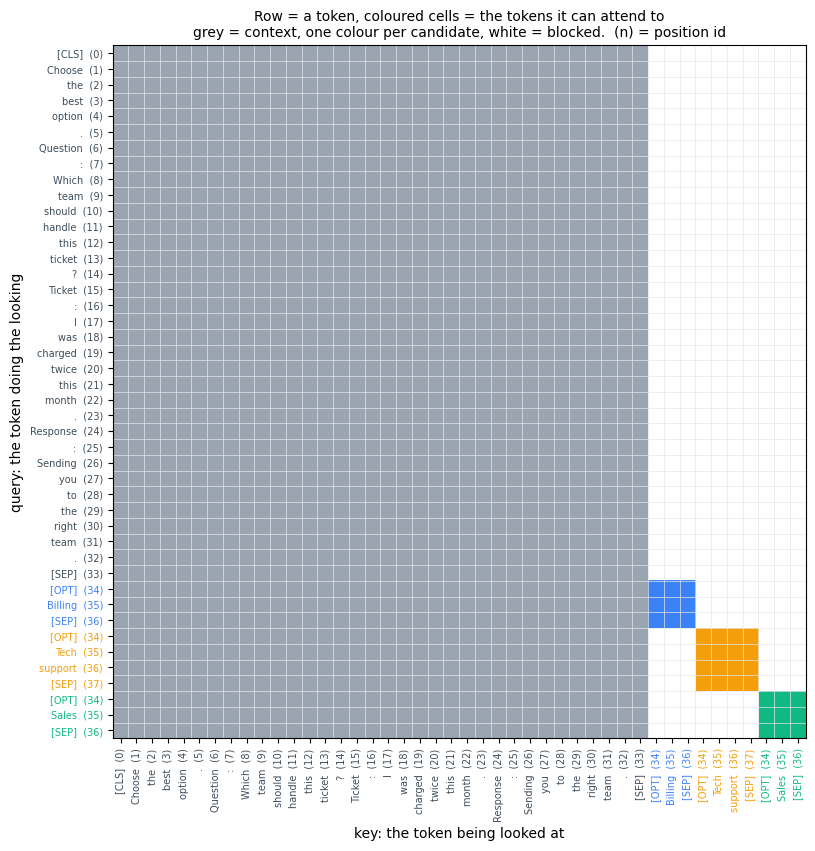

real example: context sees a candidate?       False
              candidate 1 sees candidate 2?   False
              candidate 1 sees all context?   True


In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

# A short made-up question, encoded with the same code as training, so every token fits on the axes
toy = arch.encode_example("Ticket: I was charged twice this month. Response: Sending you to the right team.",
                          "Which team should handle this ticket?", ["Billing", "Tech support", "Sales"], "choice",
                          d["max_state_tokens"], d["max_choice_tokens"])
toy_ids, toy_pos, toy_n = toy["input_ids"], toy["position_ids"], toy["context_len"]
L = len(toy_ids)
mask = arch.tokenization.attention_mask_for(toy, L).numpy()

owner = np.zeros(L, dtype=int)                     # 0 = context, i = candidate i
for i, (start, end) in enumerate(toy["blocks"], 1):
    owner[start:end] = i
colors = ["#9aa5b1", "#3b82f6", "#f59e0b", "#10b981"]
# colour of an allowed cell = who the KEY belongs to; white = blocked
grid = np.where(mask, owner[None, :] + 1, 0)
token_text = lambda t: "[OPT]" if t == arch.tokenization.OPT_TOKEN_ID else tokenizer.convert_ids_to_tokens(t).replace("▁", "")
labels = [f"{token_text(t)}  ({p})" for t, p in zip(toy_ids, toy_pos)]

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(grid, cmap=ListedColormap(["white", *colors]), vmin=0, vmax=4, interpolation="nearest")
ax.set_xticks(range(L), labels, rotation=90, fontsize=7)
ax.set_yticks(range(L), labels, fontsize=7)
for tick_labels in (ax.get_xticklabels(), ax.get_yticklabels()):
    for label, o in zip(tick_labels, owner):
        label.set_color(colors[o] if o else "#3e4c59")
ax.set_xticks(np.arange(L + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(L + 1) - 0.5, minor=True)
ax.grid(which="minor", color="#e4e7eb", lw=0.5)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("key: the token being looked at")
ax.set_ylabel("query: the token doing the looking")
ax.set_title("Row = a token, coloured cells = the tokens it can attend to\n"
             "grey = context, one colour per candidate, white = blocked.  (n) = position id", fontsize=10)
plt.show()

# The same rules, checked on the real 313-token example above
real = arch.tokenization.attention_mask_for(encoded, len(ids))
(a0, a1), (b0, b1) = encoded["blocks"][:2]
print("real example: context sees a candidate?      ", bool(real[:n, n:].any()))
print("              candidate 1 sees candidate 2?  ", bool(real[a0:a1, b0:b1].any()))
print("              candidate 1 sees all context?  ", bool(real[a0:a1, :n].all()))


## 3. Training

`train_or_load` reuses the latest finished run called `RUN_NAME`. If there isn't one, it calls `train.train(config)`: the same function as `uv run python train.py configs/deberta_walkthrough.yaml`. During training it:

1. fine-tunes **every** DeBERTa weight (lr 3e-5) and the new head (lr 1e-3), 16 questions per step, in batches of questions with similar length (less padding);
2. evaluates on validation every 100 steps and keeps the checkpoint with the **lowest validation loss** (NLL) in `checkpoints/best`, since we use the probabilities, not only the top answer;
3. logs everything to `runs/<run>/metrics.jsonl`. Each `train` line averages all the questions since the previous line.

After 20 steps it prints a time estimate. Watch the GPU in Activity Monitor → Window → GPU History.

In [6]:
run_dir = train_or_load(config, RUN_NAME, retrain=RETRAIN)
best_dir = run_dir / "checkpoints" / "best"

Experiment nbev-walkthrough-20261122-184539 -> runs/nbev-walkthrough-20261122-184539
Architecture: nbev (microsoft/deberta-v3-base)


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 198/198 [00:00<00:00, 14061.50it/s]


[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Using the latest cached version of the dataset since avbiswas/bev-decision-150K couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /Users/ahmadmezher/.cache/huggingface/datasets/avbiswas___bev-decision-150_k/default/0.0.0/11ed9b5b879e7f9524e7c89c1037d498c54206f0 (last modified on Sun Nov 22 18:30:02 2026).


... (76 outputs left out)

step=625 | time=1066.3000 | split=train_epoch | epoch=0 | loss=0.9507 | accuracy=0.5473


step=625 | time=1092.4000 | split=validation | loss=0.8217 | accuracy=0.6360 | accuracy_choice=0.6058 | nll_choice=0.9472 | ece_choice=0.0633 | accuracy_noul=0.7286 | nll_noul=0.5318 | brier_noul=0.1788 | ece_noul=0.1027 | auc_noul=0.7778 | accuracy_score=0.5054 | nll_score=1.1615 | ece_score=0.1054 | mae_score=0.8688


Saved checkpoint -> runs/nbev-walkthrough-20261122-184539/checkpoints/best


Saved checkpoint -> runs/nbev-walkthrough-20261122-184539/checkpoints/final


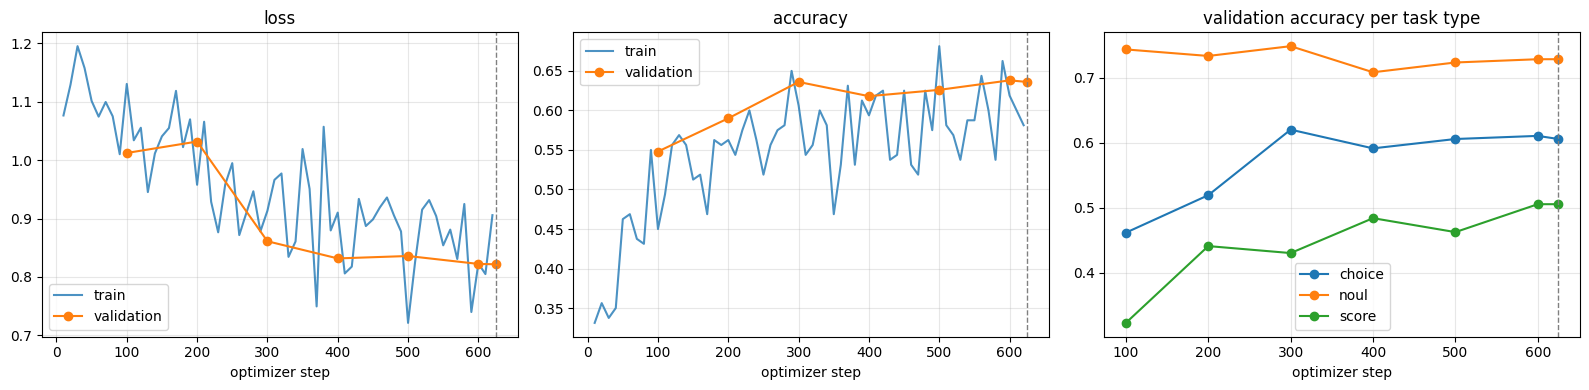

In [7]:
plot_training_curves(run_dir)

## 4. The trained model

`load_checkpoint` rebuilds the network from the checkpoint's `config.yaml`, loads `weights.safetensors` (the full fine-tuned DeBERTa and the head), and applies the temperatures from `calibration.json` if step 5 has already saved them.

In [8]:
network, config = load_checkpoint(best_dir, device)
print(f"loaded {best_dir}  (step {json.loads((best_dir / 'meta.json').read_text())['step']})")
parameter_table(network)

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

Loading weights:   2%|▏         | 3/198 [00:00<00:07, 24.93it/s]

Loading weights: 100%|██████████| 198/198 [00:00<00:00, 1576.92it/s]


[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


loaded runs/nbev-walkthrough-20261122-184539/checkpoints/best  (step 625)


,block,type,parameters,trainable
0,backbone.embeddings,DebertaV2Embeddings,"98,382,336","98,382,336"
1,backbone.encoder,DebertaV2Encoder,"85,449,216","85,449,216"
2,head.input_norm,LayerNorm,"1,536","1,536"
3,head.layers,ModuleList,"4,731,904","4,731,904"
4,head.final_norm,LayerNorm,"1,536","1,536"
5,head.scorer,Sequential,"394,241","394,241"
6,total,,"188,960,769","188,960,769"


**Layer by layer** ([torchinfo](https://github.com/TylerYep/torchinfo)), from one forward pass on 4 questions. `B` = 4 questions, one packed DeBERTa sequence of `L` tokens each, `C` = the most candidates any of them has.

In [9]:
from dataset import QuestionDataset

batch = arch.collate_fn([QuestionDataset(examples, arch.encode_example, d["max_state_tokens"], d["max_choice_tokens"])[i] for i in range(4)])
print({key: tuple(value.shape) for key, value in batch.items()}, "\n")
layer_summary(network, batch, device)

{'input_ids': (4, 115), 'position_ids': (4, 115), 'padding_mask': (4, 115), 'attention_mask': (4, 115, 115), 'opt_idx': (4, 4), 'choice_token_mask': (4, 4, 115), 'choice_mask': (4, 4), 'task_type': (4,), 'labels': (4,)} 

Layer (type (var_name))                                                Output Shape              Param #
NBEVNetwork (NBEVNetwork)                                              [4, 4]                    --
├─DebertaV2Model (backbone)                                            --                        --
│    └─DebertaV2Embeddings (embeddings)                                [4, 115, 768]             --
│    │    └─Embedding (word_embeddings)                                [4, 115, 768]             98,380,800
│    │    └─LayerNorm (LayerNorm)                                      [4, 115, 768]             1,536
│    │    └─Dropout (dropout)                                          [4, 115, 768]             --
│    └─DebertaV2Encoder (encoder)                             

**Reading the head in the summary above** (`B` questions × `C` candidate slots; padded slots are masked):

| row | what it does |
|---|---|
| `input_norm` | normalises the `[OPT]` vectors `[B, C, 768]` |
| `AttentionBlock` ×2: `norm1` → `attn` | candidates attend to each other (q·kᵀ over candidates, padding masked), added back as a residual |
| `AttentionBlock` ×2: `norm2` → `mlp` | per-candidate MLP 768 → 512 → 768 (GELU = activation, not attention), residual |
| `final_norm` → `scorer` | MLP 768 → 512 → **1**: one logit per candidate, `[B, C]` |

**Head attention on a real question**: row = candidate being updated, column = candidate it reads (rows sum to 1). The only place where candidates see each other. If it is near one-hot, try `head.num_layers: 0` to check it helps.

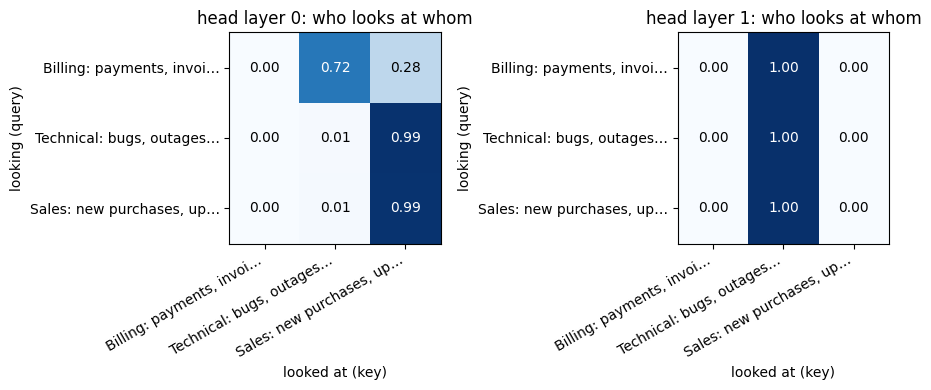

In [12]:
ticket = ("Hi, I was charged twice for my March invoice (order #4821). I have contacted you three times already "
          "and nobody answers. If this is not refunded by Friday I will cancel my subscription.")
teams = {"Billing": "payments, invoices, refunds", "Technical": "bugs, outages, login problems",
         "Sales": "new purchases, upgrades, pricing questions"}
weights, candidates = head_attention(network, config, device, ticket, "Which department should handle this ticket?", "choice", teams)
plot_head_attention(weights, candidates)

## 5. Calibration

The model's probabilities are used directly: P(yes) for yes/no questions, and the expected score for score questions. They're only trustworthy if the model is **calibrated**: of all the answers given with 80% confidence, about 80% should be right. Fine-tuned models are usually over-confident. Accuracy and AUC can't show this, because they only use the ranking of the probabilities.

**Temperature scaling** fixes it after training, with one number per question type: `p = softmax(z / T)`. T > 1 softens the probabilities, T < 1 sharpens them, and the most probable answer never changes. Each T is fitted on the **calibration** split, which was used neither for training nor for picking the checkpoint.

What to look at:

| metric | meaning |
|---|---|
| `nll_*` | negative log-likelihood (lower = better probabilities) |
| `brier_noul` | squared error of P(yes) (lower = better) |
| `mae_score` | error of the expected score (lower = better) |
| `ece_*` | average gap between confidence and accuracy (0 = calibrated; noisy on small sets) |

In [11]:
calibration = evaluate_split(network, config, best_dir, "calibration", NUM_CALIBRATION, device)  # cached after the first run

if isinstance(network.temperature, dict):   # calibration.json already exists: keep it, don't overwrite
    temperatures = network.temperature
    print("Temperatures loaded from calibration.json")
else:
    temperatures = fit_temperatures(calibration["logits"], calibration["labels"], calibration["task_types"])
    save_temperatures(best_dir, temperatures, split="calibration", num_questions=len(calibration["labels"]))
    network.temperature = temperatures       # answer() uses them from now on
    print("Temperatures fitted and saved to calibration.json")

print({task: round(t, 3) for task, t in temperatures.items()})
pd.DataFrame({"before (T = 1)": compute_metrics(calibration["logits"], calibration["labels"], calibration["task_types"]),
              "after": compute_metrics(calibration["logits"], calibration["labels"], calibration["task_types"], temperatures)}).T

Using the latest cached version of the dataset since avbiswas/bev-decision-150K couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /Users/ahmadmezher/.cache/huggingface/datasets/avbiswas___bev-decision-150_k/default/0.0.0/11ed9b5b879e7f9524e7c89c1037d498c54206f0 (last modified on Sun Nov 22 18:30:02 2026).


Temperatures fitted and saved to calibration.json
{'choice': 1.358, 'noul': 1.23, 'score': 0.896}


,loss,accuracy,accuracy_choice,nll_choice,ece_choice,accuracy_noul,nll_noul,brier_noul,ece_noul,auc_noul,accuracy_score,nll_score,ece_score,mae_score
before (T = 1),0.8600,0.5810,0.5749,0.9673,0.0746,0.6800,0.5838,0.1995,0.0749,0.7339,0.3817,1.2151,0.0942,0.9043
after,0.8514,0.5810,0.5749,0.9519,0.0364,0.6800,0.5791,0.1972,0.0775,0.7339,0.3817,1.2132,0.1186,0.8920


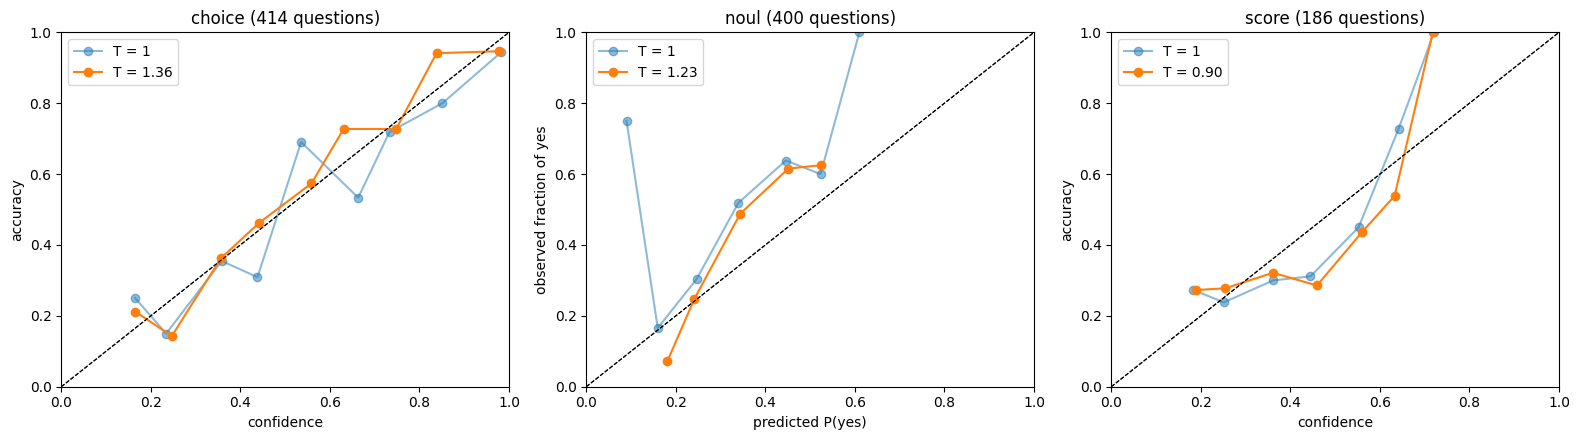

In [12]:
plot_calibration(calibration, temperatures)

## 6. Test

The test split is measured once, after every decision (checkpoint, temperatures) was made on other splits. The results are saved to `runs/<run>/test_metrics.json`, unless that file already exists.

In [13]:
test = evaluate_split(network, config, best_dir, "test", NUM_TEST, device)  # cached after the first run
test_metrics = compute_metrics(test["logits"], test["labels"], test["task_types"], temperatures)
print(f"{len(test['labels'])} test questions, {test['seconds_per_question'] * 1000:.0f} ms per question")

results_file = run_dir / "test_metrics.json"
if not results_file.exists():
    results_file.write_text(json.dumps({"checkpoint": str(best_dir), "temperatures": temperatures, "metrics": test_metrics}, indent=2))
pd.DataFrame({"test (calibrated)": test_metrics}).T

Using the latest cached version of the dataset since avbiswas/bev-decision-150K couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /Users/ahmadmezher/.cache/huggingface/datasets/avbiswas___bev-decision-150_k/default/0.0.0/11ed9b5b879e7f9524e7c89c1037d498c54206f0 (last modified on Sun Nov 22 18:30:02 2026).


1000 test questions, 50 ms per question


,loss,accuracy,accuracy_choice,nll_choice,ece_choice,accuracy_noul,nll_noul,brier_noul,ece_noul,auc_noul,accuracy_score,nll_score,ece_score,mae_score
test (calibrated),0.8347,0.6010,0.5768,0.9363,0.0335,0.7023,0.5672,0.1921,0.0626,0.7673,0.4682,1.1172,0.0509,0.8535


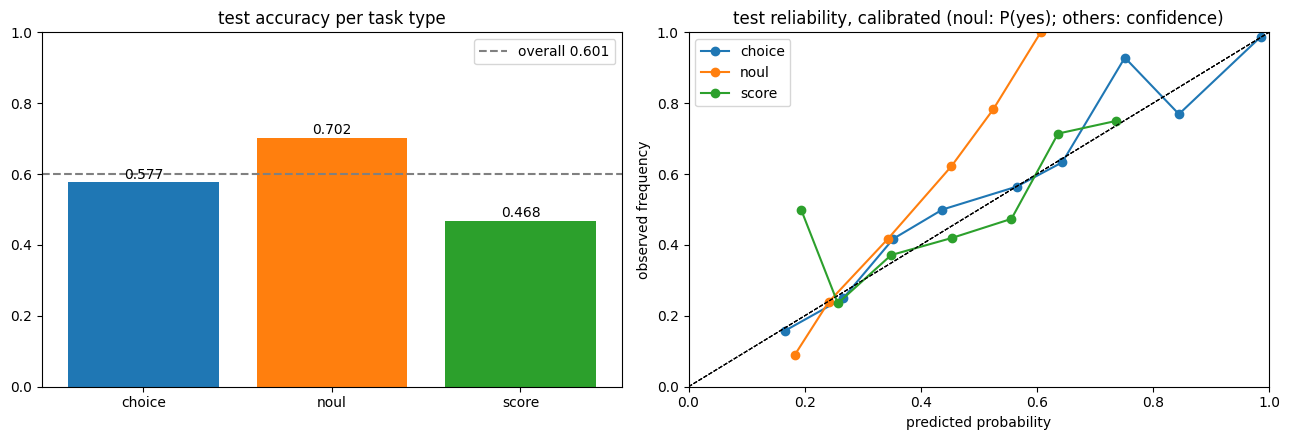

In [14]:
plot_test_results(test, test_metrics, temperatures)

### Inference speed

End to end (tokenization + one forward pass + softmax), after warm-up; batches group questions of similar length. More candidates only add their own short blocks: the context is encoded once.

In [17]:
by_batch, by_candidates = inference_speed(network, config, device, load_questions("test", 64, config["seed"]))
display(by_batch, by_candidates)

,ms per question,questions per second,mean tokens per question
batch size,,,
1,39.0349,25.6181,231.0312
8,50.4233,19.8321,231.0312


,tokens,ms per question
candidates,,
2,149,16.5539
4,173,18.4301
8,221,24.8600
16,317,33.7112
32,509,102.3230


## 7. Reading the results

Prediction = argmax over candidates (yes/no: P(yes) ≥ 0.5); no tuned threshold, and temperatures never change it. Accuracies aren't comparable across types (2 to 10 candidates, 2/3 of yes/no answers are "No"), so each is shown next to chance and the majority answer.

In [17]:
baseline_table(test, temperatures)

,questions,model accuracy,chance,majority,within-1 accuracy,MAE,MAE of 'middle level'
task,,,,,,,
choice,397,0.5768,0.2626,NaN,NaN,NaN,NaN
noul,383,0.7023,0.5000,0.6658,NaN,NaN,NaN
score,220,0.4682,0.2406,0.3682,0.8182,0.8535,1.0932


### Yes/no threshold

Good ranking (AUC ≈ 0.77), but P(yes) rarely exceeds 0.5, so argmax almost always says "No". Thresholds below are picked on the calibration split and applied to test.

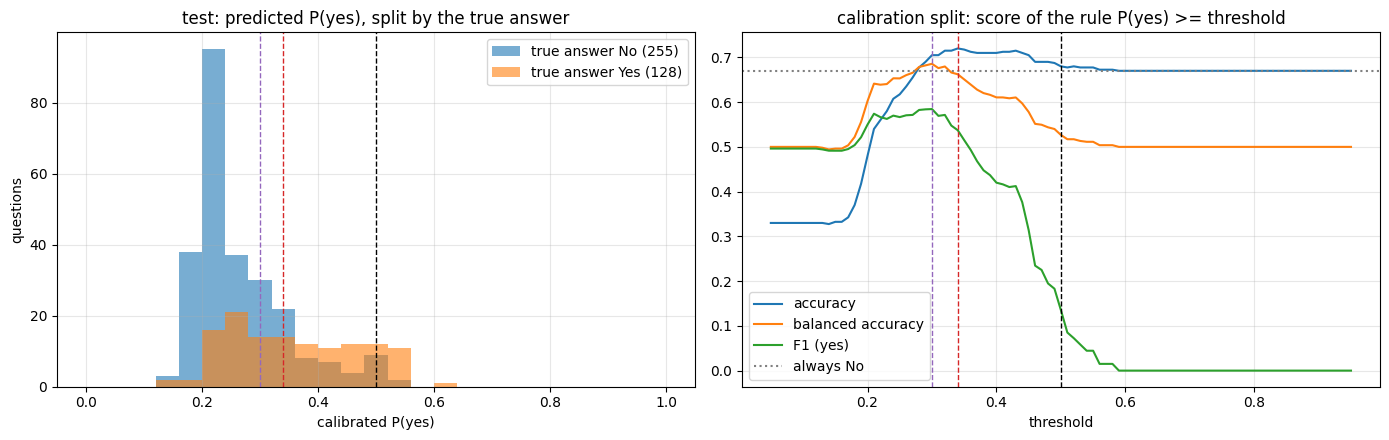

,threshold,accuracy,balanced accuracy,precision (yes),recall (yes),F1 (yes),predicted yes
argmax (0.5),0.5000,0.7023,0.5644,0.7917,0.1484,0.2500,0.0627
best accuracy on calibration,0.3400,0.7337,0.6813,0.6204,0.5234,0.5678,0.2820
best F1 (yes) on calibration,0.3000,0.6997,0.6753,0.5461,0.6016,0.5725,0.3681


In [18]:
plot_noul_threshold(calibration, test, temperatures)

### Score errors

Most errors are one level off; many scales are subjective bands (toxicity, CVSS, helpfulness).

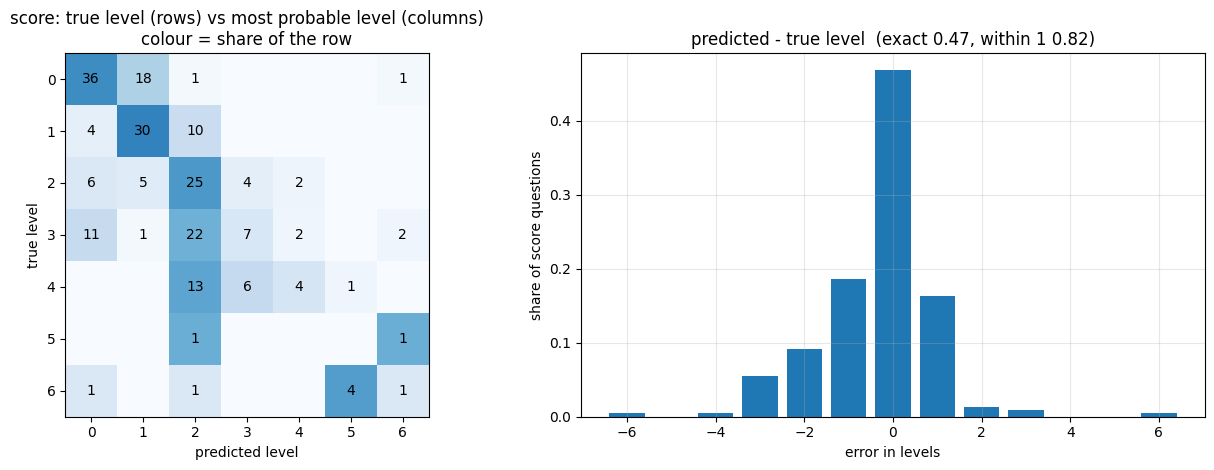

In [19]:
plot_score_errors(test, temperatures)

### Per domain and per question

`gain` = accuracy − chance. Arithmetic questions (quantity × price) sit at chance or below. Small groups: ±0.15 is noise.

In [20]:
test_questions = load_questions("test", NUM_TEST, config["seed"])   # same questions, same order as `test`
accuracy_by(test, test_questions, "domain", temperatures)

Using the latest cached version of the dataset since avbiswas/bev-decision-150K couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /Users/ahmadmezher/.cache/huggingface/datasets/avbiswas___bev-decision-150_k/default/0.0.0/11ed9b5b879e7f9524e7c89c1037d498c54206f0 (last modified on Sun Nov 22 21:52:51 2026).


,,questions,accuracy,chance,gain
domain,task,,,,
"Sentiment, emotion, and moderation",noul,164,0.7927,0.5000,0.2927
Spatial and logical reasoning,choice,132,0.4697,0.2333,0.2364
"Sentiment, emotion, and moderation",score,57,0.5088,0.2307,0.2781
"Retail, product, and shopping",noul,55,0.6727,0.5000,0.1727
Tool and workflow decisions,choice,54,0.8704,0.3256,0.5448
"Retail, product, and shopping",choice,53,0.3019,0.2091,0.0928
Support and intent routing,choice,49,0.8367,0.2469,0.5898
Reading comprehension,noul,43,0.5581,0.5000,0.0581
Response preference and quality,score,42,0.3571,0.2000,0.1571


In [21]:
with pd.option_context("display.max_colwidth", 100):
    display(accuracy_by(test, test_questions, "instructions", temperatures, min_questions=10).head(20))

,,questions,accuracy,chance,gain
instructions,task,,,,
Which test fails on the buggy version and passes after the fix?,choice,34,0.6471,0.2500,0.3971
Is the source-assigned CVSS base severity high or critical?,noul,28,0.5357,0.5000,0.0357
What is the source-assigned CVSS base-severity band?,score,28,0.3571,0.2500,0.1071
Did source annotators rate this comment as threat (at least 0.7)?,noul,24,0.9583,0.5000,0.4583
Did source annotators rate this comment as toxic (at least 0.7)?,noul,24,0.6250,0.5000,0.1250
Which band matches the source annotators' toxicity rating for this comment?,score,24,0.5833,0.2500,0.3333
Which stock item has the largest absolute line value (quantity × unit price)?,choice,23,0.0870,0.2478,-0.1609
Does the invoice identifier mark this as a cancellation?,noul,23,0.7391,0.5000,0.2391
Into which band does the sum of absolute line values fall in GBP?,score,23,0.6087,0.2500,0.3587


## 8. Ask your own questions

`ask(network, config, device, state, instructions, type, criteria)` prints the calibrated answer:

* `"choice"`: `criteria = {"option": "description", …}` (descriptions may be empty)
* `"score"`: `criteria = ["lowest level", …, "highest level"]`
* `"noul"`: no criteria; the answer is P(yes)

In [15]:
state = ("Hi, I was charged twice for my March invoice (order #4821). I have contacted you three times already "
         "and nobody answers. If this is not refunded by Friday I will cancel my subscription.")
departments = {"Billing": "payments, invoices, refunds",
               "Technical": "bugs, outages, login problems",
               "Sales": "new purchases, upgrades, pricing questions"}

ask(network, config, device, state, "Which department should handle this ticket?", "choice", departments)
ask(network, config, device, state, "Is the customer asking for a refund?", "noul")
ask(network, config, device, state, "How frustrated is the customer?", "score",
    ["calm", "slightly annoyed", "annoyed", "very frustrated", "furious"]);

[choice] Which department should handle this ticket?
    0.975  █████████████████████████████   Billing
    0.010                                  Technical
    0.015                                  Sales

[noul] Is the customer asking for a refund?
   P(yes) = 0.342  ██████████



[score] How frustrated is the customer?
    0.077  ██                              0: calm
    0.234  ███████                         1: slightly annoyed
    0.263  ████████                        2: annoyed
    0.238  ███████                         3: very frustrated
    0.188  ██████                          4: furious
   expected score = 2.22



**Order doesn't matter**: every candidate gets the same positions in the encoder, and the decision head has no positional information, so shuffling the candidates gives each one the same probability (up to bf16 rounding on the GPU).

In [16]:
shuffled = {key: departments[key] for key in ["Sales", "Billing", "Technical"]}
p1 = ask(network, config, device, state, "Which department should handle this ticket?", "choice", departments)["probabilities"]
p2 = ask(network, config, device, state, "Which department should handle this ticket?", "choice", shuffled)["probabilities"]
print("largest difference:", max(abs(p1[k] - p2[k]) for k in p1))

[choice] Which department should handle this ticket?
    0.975  █████████████████████████████   Billing
    0.010                                  Technical
    0.015                                  Sales

[choice] Which department should handle this ticket?
    0.015                                  Sales
    0.975  █████████████████████████████   Billing
    0.010                                  Technical

largest difference: 6.80685043334961e-05


In [17]:
# Your turn: change anything and run again
ask(network, config, device,
    state="The patient reports chest pain radiating to the left arm, sweating and shortness of breath for 20 minutes.",
    instructions="What is the most appropriate next step?",
    task_type="choice",
    criteria={"Call emergency services": "", "Book a routine appointment": "", "Rest and drink water": ""});

[choice] What is the most appropriate next step?
    0.452  ██████████████                  Call emergency services
    0.228  ███████                         Book a routine appointment
    0.320  ██████████                      Rest and drink water



## Going further

- **More data first**: 10K of ~250K questions, one epoch, no over-fitting yet. Raise `max_train_questions` (~0.14 s/question) and set `RETRAIN = True`.
- **Hyperparameters** (choose on validation): `lr_backbone` 1e-5–5e-5, `max_state_tokens` 512–1024, `head.num_layers` 0/1, `pooling: opt_mean`, `deberta-v3-large`.
- **Model ideas**: ordinal loss for score, class balancing for yes/no, task embedding in the head.
- **Baselines**: `head.type: bilinear_answer` (BEV head), `architecture: deberta_cross` (~3× slower); see `configs/compare/`.